# Amazon Reviews Text Classification

This project aims to classify Amazon product reviews into their top-level categories (Cat1) using machine learning techniques.

The dataset consists of:
- 40,000 training samples
- 10,000 validation samples

## 1. Data Loading

In [1]:
!pip install scikit-learn


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split

In [3]:

train_df = pd.read_csv("train_40k.csv")
val_df = pd.read_csv("val_10k.csv")

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

Train shape: (40000, 10)
Validation shape: (10000, 10)


## 2. Exploratory Data analysis (EDA)

In [4]:
train_df.head()

,productId,Title,userId,Helpfulness,Score,Time,Text,Cat1,Cat2,Cat3
0,B000E46LYG,Golden Valley Natural Buffalo Jerky,A3MQDNGHDJU4MK,0/0,3.0,-1,The description and photo on this product need...,grocery gourmet food,meat poultry,jerky
1,B000GRA6N8,Westing Game,unknown,0/0,5.0,860630400,This was a great book!!!! It is well thought t...,toys games,games,unknown
2,B000GRA6N8,Westing Game,unknown,0/0,5.0,883008000,"I am a first year teacher, teaching 5th grade....",toys games,games,unknown
3,B000GRA6N8,Westing Game,unknown,0/0,5.0,897696000,I got the book at my bookfair at school lookin...,toys games,games,unknown
4,B00000DMDQ,I SPY A is For Jigsaw Puzzle 63pc,unknown,2/4,5.0,911865600,Hi! I'm Martine Redman and I created this puzz...,toys games,puzzles,jigsaw puzzles


In [5]:
train_df.isnull().sum()

productId       0
Title          16
userId          0
Helpfulness     0
Score           0
Time            0
Text            0
Cat1            0
Cat2            0
Cat3            0
dtype: int64

In [6]:
train_df['Cat1'].value_counts()

Cat1
toys games              10266
health personal care     9772
beauty                   5846
baby products            5637
pet supplies             4862
grocery gourmet food     3617
Name: count, dtype: int64

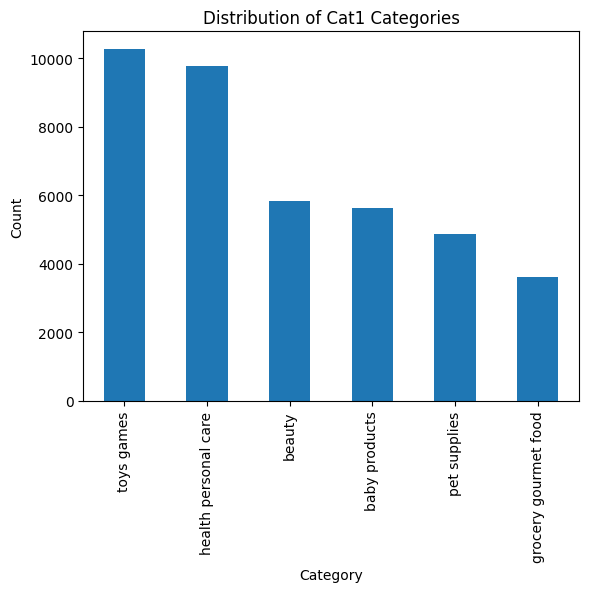

In [7]:
train_df['Cat1'].value_counts().plot(kind='bar')
plt.title("Distribution of Cat1 Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

In [8]:
train_df['Cat2'].value_counts().head(10)


Cat2
personal care                 2852
dogs                          2610
nutrition wellness            2203
health care                   2002
cats                          1779
hair care                     1773
games                         1525
skin care                     1341
medical supplies equipment    1289
fragrance                     1237
Name: count, dtype: int64

In [9]:
train_df['Cat3'].value_counts().head(10)


Cat3
unknown                 2262
shaving hair removal    1565
vitamins supplements    1315
board games              924
styling tools            850
women s                  737
face                     729
toys                     680
figures                  653
dolls                    653
Name: count, dtype: int64

In [10]:
train_df['text_length'] = train_df['Text'].apply(len)
train_df['text_length'].describe()

count    40000.000000
mean       435.201875
std        389.352078
min          1.000000
25%        188.000000
50%        323.000000
75%        545.000000
max       6589.000000
Name: text_length, dtype: float64

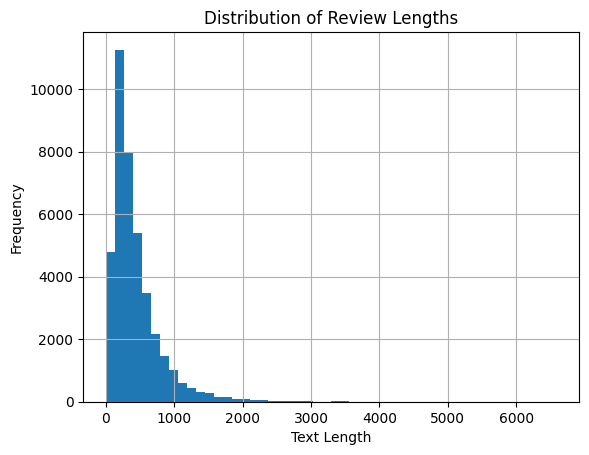

In [11]:
train_df['text_length'].hist(bins=50)
plt.title("Distribution of Review Lengths")
plt.xlabel("Text Length")
plt.ylabel("Frequency")
plt.show()



## 3. Data Cleaning And Preprocessing

In [12]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

train_df['clean_text'] = train_df['Text'].apply(clean_text)
val_df['clean_text'] = val_df['Text'].apply(clean_text)



In [13]:
print("Original:")
print(train_df['Text'].iloc[0])

print("\nCleaned:")
print(train_df['clean_text'].iloc[0])


Original:
The description and photo on this product needs to be changed to indicate this product is the BuffalOs version of this beef jerky.

Cleaned:
the description and photo on this product needs to be changed to indicate this product is the buffalos version of this beef jerky


In [14]:
print(train_df.columns)
print(val_df.columns)

Index(['productId', 'Title', 'userId', 'Helpfulness', 'Score', 'Time', 'Text',
       'Cat1', 'Cat2', 'Cat3', 'text_length', 'clean_text'],
      dtype='str')
Index(['productId', 'Title', 'userId', 'Helpfulness', 'Score', 'Time', 'Text',
       'Cat1', 'Cat2', 'Cat3', 'clean_text'],
      dtype='str')


## 4. Feature Engineering (Text Vectorisation)

In [15]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words='english', max_features=5000)

X_train_vec = vectorizer.fit_transform(train_df['clean_text'])
X_val_vec = vectorizer.transform(val_df['clean_text'])

print("Training shape:", X_train_vec.shape)
print("Validation shape:", X_val_vec.shape)



Training shape: (40000, 5000)
Validation shape: (10000, 5000)


## 4.2 TF-IDF Vectorisation

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english', max_features=5000)

X_train_tfidf = tfidf.fit_transform(train_df['clean_text'])
X_val_tfidf = tfidf.transform(val_df['clean_text'])

print(X_train_tfidf.shape)
print(X_val_tfidf.shape)

(40000, 5000)
(10000, 5000)


## 5. Model Training - Multinomial Naive Bayes

In [17]:
!pip install seaborn


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import seaborn as sns

In [19]:
import sys
!{sys.executable} -m pip install seaborn


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


## 5.1 Multinomial Naive Bayes (BOW) - Model Training 

In [20]:
from sklearn.naive_bayes import MultinomialNB
# Create model
nb_model = MultinomialNB()
# Train model on training data
nb_model.fit(X_train_vec, train_df['Cat1'])


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [21]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_nb = nb_model.predict(X_val_vec)

accuracy_nb = accuracy_score(val_df['Cat1'], y_pred_nb)

print("Naive Bayes Accuracy:", accuracy_nb)
print("\nClassification Report:\n")
print(classification_report(val_df['Cat1'], y_pred_nb))


Naive Bayes Accuracy: 0.7698

Classification Report:

                      precision    recall  f1-score   support

       baby products       0.55      0.68      0.61       698
              beauty       0.79      0.82      0.81      2135
grocery gourmet food       0.67      0.82      0.74       840
health personal care       0.79      0.66      0.72      2992
        pet supplies       0.88      0.81      0.84      1576
          toys games       0.79      0.87      0.82      1759

            accuracy                           0.77     10000
           macro avg       0.75      0.78      0.76     10000
        weighted avg       0.78      0.77      0.77     10000



## 5.1.2 Multinomial Naive Bayes (TF-IDF)

In [38]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_train_tfidf, train_df['Cat1'])

y_pred_nb_tfidf = nb_tfidf.predict(X_val_tfidf)

print("Naive Bayes TF-IDF Accuracy:", accuracy_score(val_df['Cat1'], y_pred_nb_tfidf))
print(classification_report(val_df['Cat1'], y_pred_nb_tfidf))

Naive Bayes TF-IDF Accuracy: 0.6668
                      precision    recall  f1-score   support

       baby products       0.75      0.44      0.55       698
              beauty       0.92      0.55      0.69      2135
grocery gourmet food       0.96      0.23      0.37       840
health personal care       0.57      0.89      0.69      2992
        pet supplies       0.99      0.43      0.60      1576
          toys games       0.61      0.94      0.74      1759

            accuracy                           0.67     10000
           macro avg       0.80      0.58      0.61     10000
        weighted avg       0.76      0.67      0.65     10000



## 5.2 Logistic Regression (TF-IDF) - Model Training 

In [22]:
lr_tfidf = LogisticRegression(max_iter=1000)

lr_tfidf.fit(X_train_tfidf, train_df['Cat1'])

y_pred_tfidf = lr_tfidf.predict(X_val_tfidf)

accuracy_tfidf = accuracy_score(val_df['Cat1'], y_pred_tfidf)

print("TF-IDF Logistic Regression Accuracy:", accuracy_tfidf)
print("\nClassification Report:\n")
print(classification_report(val_df['Cat1'], y_pred_tfidf))

TF-IDF Logistic Regression Accuracy: 0.7872

Classification Report:

                      precision    recall  f1-score   support

       baby products       0.67      0.63      0.65       698
              beauty       0.85      0.76      0.81      2135
grocery gourmet food       0.79      0.70      0.74       840
health personal care       0.71      0.83      0.77      2992
        pet supplies       0.94      0.77      0.85      1576
          toys games       0.80      0.86      0.83      1759

            accuracy                           0.79     10000
           macro avg       0.79      0.76      0.77     10000
        weighted avg       0.80      0.79      0.79     10000



## 5.2.2 Logistic Regression (BOW)

In [39]:
from sklearn.linear_model import LogisticRegression

lr_bow = LogisticRegression(max_iter=1000)
lr_bow.fit(X_train_bow, train_df['Cat1'])

y_pred_lr_bow = lr_bow.predict(X_val_bow)

print("Logistic Regression BoW Accuracy:", accuracy_score(val_df['Cat1'], y_pred_lr_bow))
print(classification_report(val_df['Cat1'], y_pred_lr_bow))

Logistic Regression BoW Accuracy: 0.782
                      precision    recall  f1-score   support

       baby products       0.62      0.64      0.63       698
              beauty       0.81      0.77      0.79      2135
grocery gourmet food       0.77      0.72      0.75       840
health personal care       0.73      0.80      0.76      2992
        pet supplies       0.91      0.79      0.84      1576
          toys games       0.83      0.84      0.83      1759

            accuracy                           0.78     10000
           macro avg       0.78      0.76      0.77     10000
        weighted avg       0.79      0.78      0.78     10000



## Confusion Matrix - Logistic Regression

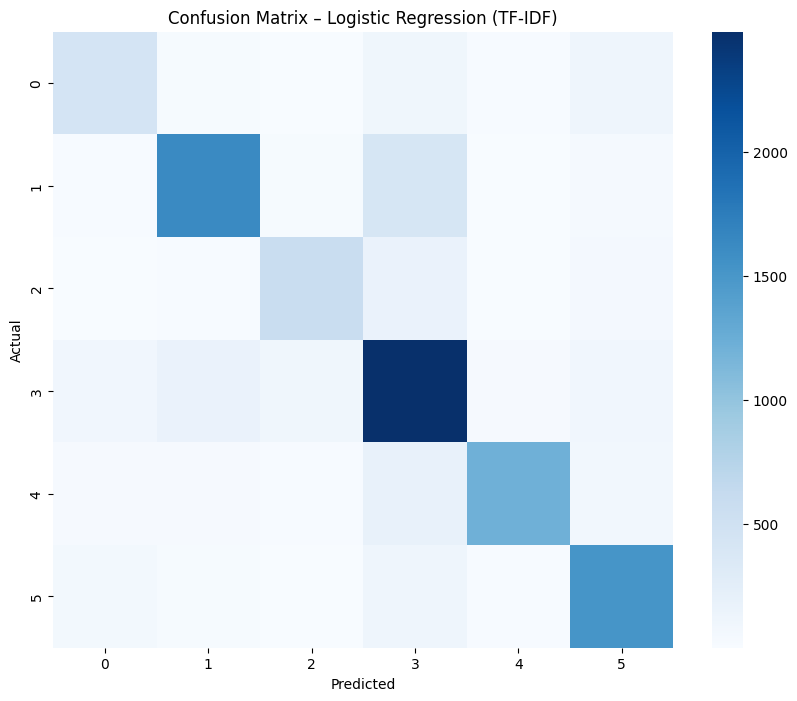

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(val_df['Cat1'], y_pred_tfidf)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=False, cmap="Blues")
plt.title("Confusion Matrix – Logistic Regression (TF-IDF)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 5.3 Linear SVM (TF-IDF) - Model Training 

In [24]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, train_df['Cat1'])

y_pred_svm = svm_model.predict(X_val_tfidf)

accuracy_svm = accuracy_score(val_df['Cat1'], y_pred_svm)

print("Linear SVM Accuracy:", accuracy_svm)
print("\nClassification Report:\n")
print(classification_report(val_df['Cat1'], y_pred_svm))

Linear SVM Accuracy: 0.7851

Classification Report:

                      precision    recall  f1-score   support

       baby products       0.61      0.65      0.63       698
              beauty       0.83      0.77      0.80      2135
grocery gourmet food       0.75      0.73      0.74       840
health personal care       0.74      0.79      0.76      2992
        pet supplies       0.91      0.81      0.85      1576
          toys games       0.81      0.85      0.83      1759

            accuracy                           0.79     10000
           macro avg       0.77      0.77      0.77     10000
        weighted avg       0.79      0.79      0.79     10000



## 5.3.2 Linear SVM (BOW)

In [40]:
from sklearn.svm import LinearSVC

svm_bow = LinearSVC()
svm_bow.fit(X_train_bow, train_df['Cat1'])

y_pred_svm_bow = svm_bow.predict(X_val_bow)

print("SVM BoW Accuracy:", accuracy_score(val_df['Cat1'], y_pred_svm_bow))
print(classification_report(val_df['Cat1'], y_pred_svm_bow))

SVM BoW Accuracy: 0.7662
                      precision    recall  f1-score   support

       baby products       0.55      0.66      0.60       698
              beauty       0.79      0.76      0.78      2135
grocery gourmet food       0.73      0.72      0.73       840
health personal care       0.73      0.76      0.75      2992
        pet supplies       0.87      0.79      0.83      1576
          toys games       0.82      0.81      0.82      1759

            accuracy                           0.77     10000
           macro avg       0.75      0.75      0.75     10000
        weighted avg       0.77      0.77      0.77     10000



/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


## Logistic Regression for Cat2

In [31]:
y_train_cat2 = train_df['Cat2']
y_val_cat2 = val_df['Cat2']


In [27]:
lr_cat2 = LogisticRegression(max_iter=1000)

lr_cat2.fit(X_train_tfidf, train_df['Cat2'])

y_pred_cat2 = lr_cat2.predict(X_val_tfidf)

accuracy_cat2 = accuracy_score(val_df['Cat2'], y_pred_cat2)

print("TF-IDF Logistic Regression Accuracy (Cat2):", accuracy_cat2)
print("\nClassification Report (Cat2):\n")
print(classification_report(val_df['Cat2'], y_pred_cat2))

TF-IDF Logistic Regression Accuracy (Cat2): 0.5845

Classification Report (Cat2):

                                  precision    recall  f1-score   support

              action toy figures       0.31      0.48      0.37       115
                     arts crafts       0.64      0.27      0.38        99
                 baby child care       0.62      0.14      0.22        37
                       baby food       0.00      0.00      0.00         2
               baby toddler toys       0.36      0.45      0.40       139
                       bath body       0.60      0.36      0.45       142
               bathing skin care       0.38      0.11      0.17        46
                       beverages       0.76      0.72      0.74       215
                           birds       0.87      0.25      0.39        51
                   breads bakery       0.31      0.18      0.23        22
                 breakfast foods       0.54      0.18      0.27        39
                   building 

/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

## Logistic Regression(BOW) Cat2

In [41]:
from sklearn.linear_model import LogisticRegression

lr_bow_cat2 = LogisticRegression(max_iter=1000)
lr_bow_cat2.fit(X_train_bow, y_train_cat2)

y_pred_lr_bow_cat2 = lr_bow_cat2.predict(X_val_bow)

print("Logistic Regression BoW (Cat2):", accuracy_score(y_val_cat2, y_pred_lr_bow_cat2))
print(classification_report(y_val_cat2, y_pred_lr_bow_cat2))

Logistic Regression BoW (Cat2): 0.5722
                                  precision    recall  f1-score   support

              action toy figures       0.33      0.47      0.39       115
                     arts crafts       0.65      0.33      0.44        99
                 baby child care       0.53      0.22      0.31        37
                       baby food       0.00      0.00      0.00         2
               baby toddler toys       0.34      0.39      0.36       139
                       bath body       0.51      0.35      0.42       142
               bathing skin care       0.44      0.17      0.25        46
                       beverages       0.67      0.65      0.66       215
                           birds       0.95      0.39      0.56        51
                   breads bakery       0.29      0.18      0.22        22
                 breakfast foods       0.55      0.28      0.37        39
                   building toys       0.58      0.42      0.48        8

/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

## Confusion Matrix: Cat2

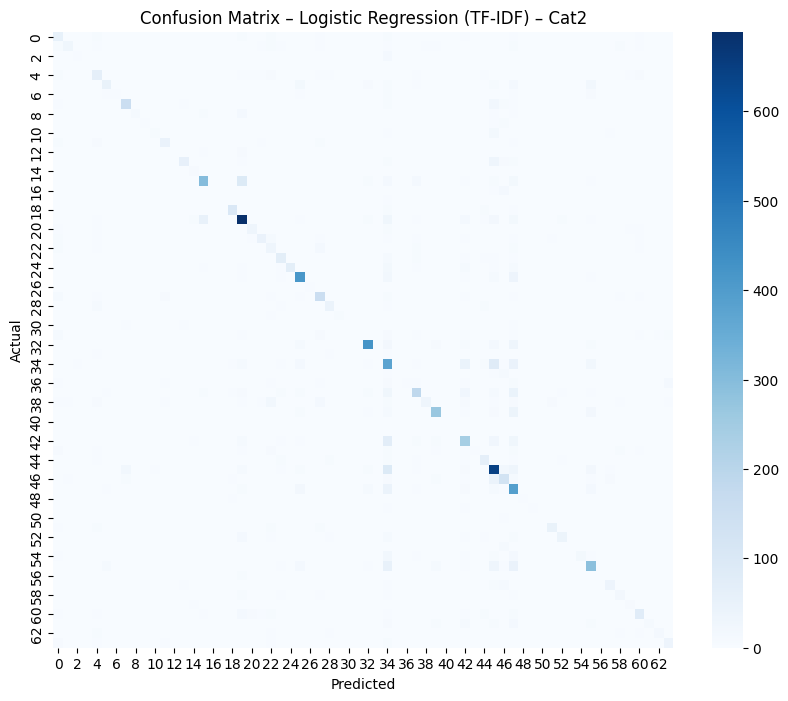

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_cat2 = confusion_matrix(val_df['Cat2'], y_pred_cat2)

plt.figure(figsize=(10,8))
sns.heatmap(cm_cat2, annot=False, cmap="Blues")
plt.title("Confusion Matrix – Logistic Regression (TF-IDF) – Cat2")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Naive Bayes (Bow for Cat2)

In [35]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# BoW
count_vectorizer = CountVectorizer(stop_words='english')

X_train_bow = count_vectorizer.fit_transform(train_df['clean_text'])
X_val_bow = count_vectorizer.transform(val_df['clean_text'])

# Model
nb_model = MultinomialNB()
nb_model.fit(X_train_bow, y_train_cat2)

# Prediction
y_pred_nb = nb_model.predict(X_val_bow)

# Evaluation
print("Naïve Bayes Cat2 Accuracy:", accuracy_score(y_val_cat2, y_pred_nb))
print(classification_report(y_val_cat2, y_pred_nb))

Naïve Bayes Cat2 Accuracy: 0.4914
                                  precision    recall  f1-score   support

              action toy figures       0.34      0.37      0.35       115
                     arts crafts       0.75      0.03      0.06        99
                 baby child care       0.00      0.00      0.00        37
                       baby food       0.00      0.00      0.00         2
               baby toddler toys       0.28      0.63      0.38       139
                       bath body       0.75      0.02      0.04       142
               bathing skin care       1.00      0.02      0.04        46
                       beverages       0.83      0.43      0.56       215
                           birds       1.00      0.02      0.04        51
                   breads bakery       0.00      0.00      0.00        22
                 breakfast foods       0.00      0.00      0.00        39
                   building toys       0.58      0.08      0.14        89
   

/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

## Naive Bayes (TF-IDF) Cat2

In [43]:
nb_tfidf_cat2 = MultinomialNB()
nb_tfidf_cat2.fit(X_train_tfidf, y_train_cat2)

y_pred_nb_tfidf_cat2 = nb_tfidf_cat2.predict(X_val_tfidf)

print("Naive Bayes TF-IDF (Cat2):", accuracy_score(y_val_cat2, y_pred_nb_tfidf_cat2))
print(classification_report(y_val_cat2, y_pred_nb_tfidf_cat2))

Naive Bayes TF-IDF (Cat2): 0.3636
                                  precision    recall  f1-score   support

              action toy figures       0.61      0.17      0.27       115
                     arts crafts       0.00      0.00      0.00        99
                 baby child care       0.00      0.00      0.00        37
                       baby food       0.00      0.00      0.00         2
               baby toddler toys       0.31      0.21      0.25       139
                       bath body       0.00      0.00      0.00       142
               bathing skin care       0.00      0.00      0.00        46
                       beverages       0.94      0.13      0.24       215
                           birds       0.00      0.00      0.00        51
                   breads bakery       0.00      0.00      0.00        22
                 breakfast foods       0.00      0.00      0.00        39
                   building toys       0.00      0.00      0.00        89
   

/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

## Linear SVM (TF-IDF for cat2)

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# TF-IDF
tfidf = TfidfVectorizer(stop_words='english')

X_train_tfidf = tfidf.fit_transform(train_df['clean_text'])
X_val_tfidf = tfidf.transform(val_df['clean_text'])

# Model
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train_cat2)

# Prediction
y_pred_svm = svm_model.predict(X_val_tfidf)

# Evaluation
print("SVM Cat2 Accuracy:", accuracy_score(y_val_cat2, y_pred_svm))
print(classification_report(y_val_cat2, y_pred_svm))

SVM Cat2 Accuracy: 0.6133
                                  precision    recall  f1-score   support

              action toy figures       0.38      0.50      0.43       115
                     arts crafts       0.54      0.40      0.46        99
                 baby child care       0.59      0.27      0.37        37
                       baby food       0.00      0.00      0.00         2
               baby toddler toys       0.38      0.45      0.41       139
                       bath body       0.51      0.40      0.45       142
               bathing skin care       0.39      0.20      0.26        46
                       beverages       0.65      0.76      0.70       215
                           birds       0.78      0.57      0.66        51
                   breads bakery       0.28      0.23      0.25        22
                 breakfast foods       0.57      0.41      0.48        39
                   building toys       0.62      0.51      0.56        89
           

## Linear SVM (BOW) Cat2

In [44]:
from sklearn.svm import LinearSVC

svm_bow_cat2 = LinearSVC()
svm_bow_cat2.fit(X_train_bow, y_train_cat2)

y_pred_svm_bow_cat2 = svm_bow_cat2.predict(X_val_bow)

print("SVM BoW (Cat2):", accuracy_score(y_val_cat2, y_pred_svm_bow_cat2))
print(classification_report(y_val_cat2, y_pred_svm_bow_cat2))

SVM BoW (Cat2): 0.5303
                                  precision    recall  f1-score   support

              action toy figures       0.34      0.41      0.37       115
                     arts crafts       0.47      0.28      0.35        99
                 baby child care       0.33      0.19      0.24        37
                       baby food       0.00      0.00      0.00         2
               baby toddler toys       0.28      0.29      0.29       139
                       bath body       0.38      0.35      0.37       142
               bathing skin care       0.19      0.13      0.16        46
                       beverages       0.62      0.69      0.65       215
                           birds       0.79      0.43      0.56        51
                   breads bakery       0.15      0.14      0.14        22
                 breakfast foods       0.42      0.38      0.40        39
                   building toys       0.46      0.44      0.45        89
            bu

/Users/mac/sudometrics_env/lib/python3.11/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


## Comparison Table

In [45]:
import pandas as pd

results = {
    "Model": [
        "Naïve Bayes", "Naïve Bayes",
        "Logistic Regression", "Logistic Regression",
        "Linear SVM", "Linear SVM"
    ],
    "Feature Type": [
        "BoW", "TF-IDF",
        "BoW", "TF-IDF",
        "BoW", "TF-IDF"
    ],
    "Cat1 Accuracy": [
        0.7698, 0.6668,
        0.7820, 0.7878,
        0.7662, 0.7845
    ],
    "Cat2 Accuracy": [
        None, 0.3636,
        0.5722, 0.5850,
        0.5303, 0.6133
    ]
}

results_df = pd.DataFrame(results)
results_df

,Model,Feature Type,Cat1 Accuracy,Cat2 Accuracy
0,Naïve Bayes,BoW,0.7698,NaN
1,Naïve Bayes,TF-IDF,0.6668,0.3636
2,Logistic Regression,BoW,0.7820,0.5722
3,Logistic Regression,TF-IDF,0.7878,0.5850
4,Linear SVM,BoW,0.7662,0.5303
5,Linear SVM,TF-IDF,0.7845,0.6133
